<a href="https://colab.research.google.com/github/lailynissaam/Analisis-Deret-Waktu/blob/main/Hands_On_Minggu_8_STA1542_Pendugaan_Parameter_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1><center> PENDUGAAN PARAMETER </center></h1><center>Laily Nissa A. Mualifah </center>

<center>
___________________________________________________________________________________________
</center>


<h1> Metode Momen </h1>

Pada metode momen, nilai parameter diduga dengan cara menyamakan nilai momen contoh dengan nilai momen teoritis.

<center>$M_1\equiv m_1$</center>
<center>$E(y)\equiv \frac{1}{n}\sum_{i=1}^n{y_i}$ </center>
<center>$M_2\equiv m_2$</center>
<center>$E(y^2)\equiv \frac{1}{n}\sum_{i=1}^n{y^2_i}$ </center>

dan seterusnya.

In [ ]:
!pip install rpy2

In [ ]:
import warnings
warnings.filterwarnings("ignore")

#Jalankan syntax ini cukup satu kali, jangan berulang
%load_ext rpy2.ipython

In [ ]:
%%R
install.packages('TSA')

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
also installing the dependencies ‘xts’, ‘TTR’, ‘quadprog’, ‘zoo’, ‘quantmod’, ‘leaps’, ‘locfit’, ‘tseries’

trying URL 'https://cran.rstudio.com/src/contrib/xts_0.14.1.tar.gz'
Content type 'application/x-gzip' length 878211 bytes (857 KB)
downloaded 857 KB

trying URL 'https://cran.rstudio.com/src/contrib/TTR_0.24.4.tar.gz'
Content type 'application/x-gzip' length 318965 bytes (311 KB)
downloaded 311 KB

trying URL 'https://cran.rstudio.com/src/contrib/quadprog_1.5-8.tar.gz'
Content type 'application/x-gzip' length 36141 bytes (35 KB)
downloaded 35 KB

trying URL 'https://cran.rstudio.com/src/contrib/zoo_1.8-14.tar.gz'
Content type 'application/x-gzip' length 778426 bytes (760 KB)
downloaded 760 KB

trying URL 'https://cran.rstudio.com/src/contrib/quantmod_0.4.27.tar.gz'
Content type 'application/x-gzip' length 156321 bytes (152 KB)
downloaded 152 KB

trying URL 'https://cran.rstudio.com/src/contrib/leaps

In [ ]:
%%R
library(TSA)


Attaching package: ‘TSA’

The following objects are masked from ‘package:stats’:

    acf, arima

The following object is masked from ‘package:utils’:

    tar



Untuk ilustrasi pendugaan parameter menggunakan metode momen dibangkitkan beberapa data simulasi dari model AR(1), AR(2), MA(1), ARMA(1,1).

In [ ]:
%%R
set.seed(100)
ma1_1=arima.sim(list(order = c(0,0,1), ma = -0.9), n = 120)
ma1_2=arima.sim(list(order = c(0,0,1), ma = 0.9), n = 120)
ma1_3=arima.sim(list(order = c(0,0,1), ma = -0.5), n = 60)
ma1_4=arima.sim(list(order = c(0,0,1), ma = 0.5), n = 60)

ar1_1=arima.sim(list(order = c(1,0,0), ar = 0.9), n = 60)
ar1_2=arima.sim(list(order = c(1,0,0), ar = -0.4), n = 60)
ar2_1=arima.sim(list(order = c(2,0,0), ar = c(1.5,-0.75)), n = 120)
ar2_2=arima.sim(list(order = c(2,0,0), ar = c(-0.25,0.5)), n = 120)

Untuk model *Autoregressive* penduga momen dari parameter model dapat dihitung menggunakan persamaan Yule-Walker, dengan $\rho_1$ disamadengankan $r_1$, $\rho_2$ disamadengankan $r_2$, dan seterusnya.

<center>$\phi_1+r_1\phi_2+r_2\phi_3+...+r_{p-1}\phi_p=r_1$</center>
<center>$r_1\phi_1+\phi_2+r_1\phi_3+...+r_{p-2}\phi_p=r_2$</center>
<center>$r_{p-1}\phi_1+r_{p-2}\phi_2+r_{p-3}\phi_3+...+\phi_p=r_p$</center>

Untuk model AR (1) penduga momen parameter adalah $\hat{\phi}=r_1$, sementara untuk model AR (2) penduga momen parameter adalah $\hat{\phi_1}=\frac{r_1(1-r_2)}{1-r_1^2}$ dan $\hat{\phi_2}=\frac{r_2-r_1^2}{1-r_1^2}$


Sementara untuk model MA (1), penduga momen dari parameter model **ada jika $|r_1|\le 0.5$**.

<center>$\hat{\theta}=\frac{-1+\sqrt{1-4r_1^2}}{2r_1}$</center>

In [ ]:
%%R
estimate_ma1_mom=function(x){r=acf(x,plot=F)$acf[1];
                             if (abs(r)<0.5) return((-1+sqrt(1-4*r^2))/(2*r))
                             else return(NA)}

In [ ]:
%%R
print(estimate_ma1_mom(ma1_1))
print(estimate_ma1_mom(ma1_2))
print(estimate_ma1_mom(ma1_3))
print(estimate_ma1_mom(ma1_4))

[1] NA
[1] -0.6841433
[1] 0.3925867
[1] -0.3475524


In [ ]:
%%R
print(ar(ar1_1,order.max=1,AIC=F,method='yw'))
print(ar(ar1_2,order.max=1,AIC=F,method='yw'))
print(ar(ar2_1,order.max=2,AIC=F,method='yw'))
print(ar(ar2_2,order.max=2,AIC=F,method='yw'))


Call:
ar(x = ar1_1, order.max = 1, method = "yw", AIC = F)

Coefficients:
     1  
0.8121  

Order selected 1  sigma^2 estimated as  1.453

Call:
ar(x = ar1_2, order.max = 1, method = "yw", AIC = F)

Coefficients:
      1  
-0.4712  

Order selected 1  sigma^2 estimated as  1.161

Call:
ar(x = ar2_1, order.max = 2, method = "yw", AIC = F)

Coefficients:
      1        2  
 1.5370  -0.7633  

Order selected 2  sigma^2 estimated as  1.213

Call:
ar(x = ar2_2, order.max = 2, method = "yw", AIC = F)

Coefficients:
      1        2  
-0.2715   0.4787  

Order selected 2  sigma^2 estimated as  1.176


- Untuk data simulasi MA (1) yang pertama, nilai parameter aslinya adalah 0.9. Hasil penduga momennya bernilai $NA$. Hal ini disebabkan karena nilai $|r_1|>0.5$, yaitu sebesar $-0.6205$
- Untuk data simulasi MA (1) yang kedua, nilai parameter aslinya adalah -0.9. Hasil penduga momennya bernilai $-0.6841$
- Untuk data simulasi MA (1) yang ketiga, nilai parameter aslinya adalah 0.5. Hasil penduga momennya bernilai $0.3926$
- Untuk data simulasi MA (1) yang keempat, nilai parameter aslinya adalah -0.5. Hasil penduga momennya bernilai $-0.3476$

Berdasarkan hasil ilustrasi di atas terlihat bahwa metode momen tidak begitu cocok diaplikasikan terhadap model *moving average*.

- Untuk data simulasi AR (1) yang pertama, nilai parameter aslinya adalah 0.9. Hasil penduga momennya bernilai $0.8121$
- Untuk data simulasi AR (1) yang kedua, nilai parameter aslinya adalah -0.4. Hasil penduga momennya bernilai $-0.4712$
- Untuk data simulasi AR (2) yang pertama, nilai parameter aslinya adalah 1.5 dan -0.75. Hasil penduga momennya bernilai $1.5370$ dan $-0.7633$
- Untuk data simulasi AR (2) yang kedua, nilai parameter aslinya adalah -0.25 dan 0.5. Hasil penduga momennya bernilai $-0.2715$ dan $0.4787$

**NB.: Dalam python tidak tersedia fungsi untuk pendugaan parameter menggunakan metode momen**

<h1> Metode Kuadrat Terkecil</h1>

Perhatikan model AR(1):

<center>$Y_t-\mu=\phi(Y_{t-1}-\mu)+e_t$</center>

Penduga kuadrat terkecil diperoleh dengan meminimalkan kuadrat dari jumlahan $(Y_t-\mu)-(\phi(Y_{t-1}-\mu)$, atau dapat dituliskan sebagai:

<center>$SSE=\sum_{i=1}^n [(Y_t-\mu)-(\phi(Y_{t-1}-\mu)]^2$</center>

Parameter 𝜙 dan 𝜇 diduga dengan nilai yang meminimalkan $SSE$ jika diberikan $𝑌_1, 𝑌_1, … , 𝑌_𝑛$. Bentuk ini dapat digeneralisasi untuk model AR(p). Penduga kuadrat terkecil dikenal juga dengan **penduga kuadrat terkecil bersyarat**.

Selanjutnya untuk model MA(1):

<center>$Y_t=e_t-\theta e_{t-1}$</center>

Jika kita perhatikan model di atas, mungkin tampak bahwa metode kudrat terkecil tidak bisa diaplikasikan pada model MA(1) tersebut. Ingat bahwa model MA (1) yang *invertible* dapat dinyatakan sebagai model autoregressive dengan order yang tidak berhingga:

<center>$Y_t=-\theta Y_{t-1}-\theta^2Y_{t-2}-\theta^3Y_{t-3}-...+e_t$</center>

Sehingga dengan cara yang sama dengan model AR di atas, penduga parameter dalam model MA dapat diduga dengan meminimalkan

<center>$SSE=\sum_{i=1}^n [Y_t+\theta Y_{t-1}+\theta^2Y_{t-2}+\theta^3Y_{t-3}+...]^2$</center>

Karena parameter dalam persamaan $SSE$ tersebut tidak linier, maka untuk meminimalkannya dapat dilakukan dengan optimisasi numerik (misalnya Newton Raphson).

In [ ]:
%%R
print(ar(ar1_1,order.max=1,AIC=F,method='ols'))
print(arima(ar1_2, order=c(1,0,0),method='CSS'))
print(ar(ar2_1,order.max=2,AIC=F,method='ols'))
print(arima(ar2_2, order=c(2,0,0),method='CSS'))


Call:
ar(x = ar1_1, order.max = 1, method = "ols", AIC = F)

Coefficients:
     1  
0.8582  

Intercept: 0.05497 (0.1468) 

Order selected 1  sigma^2 estimated as  1.271

Call:
arima(x = ar1_2, order = c(1, 0, 0), method = "CSS")

Coefficients:
          ar1  intercept
      -0.4872     0.0308
s.e.   0.1137     0.0911

sigma^2 estimated as 1.1:  part log likelihood = -88

Call:
ar(x = ar2_1, order.max = 2, method = "ols", AIC = F)

Coefficients:
      1        2  
 1.5505  -0.7755  

Intercept: 0.03269 (0.09464) 

Order selected 2  sigma^2 estimated as  1.057

Call:
arima(x = ar2_2, order = c(2, 0, 0), method = "CSS")

Coefficients:
          ar1     ar2  intercept
      -0.2719  0.4788     0.3245
s.e.   0.0801  0.0800     0.1240

sigma^2 estimated as 1.16:  part log likelihood = -179.2


- Untuk data simulasi AR (1) yang pertama, nilai parameter aslinya adalah 0.9. Hasil penduga kuadrat terkecilnya bernilai $0.8582$
- Untuk data simulasi AR (1) yang kedua, nilai parameter aslinya adalah -0.4. Hasil penduga kuadrat terkecilnya bernilai $-0.4872$
- Untuk data simulasi AR (2) yang pertama, nilai parameter aslinya adalah 1.5 dan -0.75. Hasil penduga kuadrat terkecilnya bernilai $1.5505$ dan $-0.7755$
- Untuk data simulasi AR (2) yang kedua, nilai parameter aslinya adalah -0.25 dan 0.5. Hasil penduga kuadrat terkecilnya bernilai $-0.2719$ dan $0.4788$

In [ ]:
%%R
print(arima(ma1_1, order=c(0,0,1),method='CSS'))
print(arima(ma1_2, order=c(0,0,1),method='CSS'))


Call:
arima(x = ma1_1, order = c(0, 0, 1), method = "CSS")

Coefficients:
          ma1  intercept
      -0.9373     0.0014
s.e.   0.0260     0.0063

sigma^2 estimated as 0.9839:  part log likelihood = -169.3

Call:
arima(x = ma1_2, order = c(0, 0, 1), method = "CSS")

Coefficients:
         ma1  intercept
      0.9555    -0.0179
s.e.  0.0238     0.1505

sigma^2 estimated as 0.7484:  part log likelihood = -152.88


- Untuk data simulasi MA (1) yang pertama, nilai parameter aslinya adalah 0.9. Hasil penduga kuadrat terkecilnya bernilai $0.9373$.
- Untuk data simulasi MA (1) yang kedua, nilai parameter aslinya adalah -0.9. Hasil penduga kuadrat terkecilnya bernilai $-0.9555$

In [ ]:
%%R
set.seed(123)
arma11=arima.sim(list(order = c(1,0,1), ar = 0.6, ma=0.3), n = 100)

In [ ]:
%%R
arima(arma11, order=c(1,0,1),method='CSS')


Call:
arima(x = arma11, order = c(1, 0, 1), method = "CSS")

Coefficients:
         ar1     ma1  intercept
      0.5869  0.3312     0.0478
s.e.  0.1242  0.1677     0.2922

sigma^2 estimated as 0.8265:  part log likelihood = -132.37


Deret ARMA(1,1) yang dibangkitkan memiliki nilai parameter asli $\phi=0.6$ dan $\theta=-0.3$. Hasil penduga parameter model menggunakan metode kuadrat terkecil adalah $\hat{\phi}=0.5869$ dan $\hat{\theta}=-0.3312$.

**NB.: Dalam python tidak tersedia fungsi untuk pendugaan parameter menggunakan metode kuadrat terkecil**

<h1> Metode Kemungkinan Maksimum </h1>

Fungsi kemungkinan (*likelihood*) $𝐿$ didefinisikan sebagai fungsi kepekatan peluang bersama dari data yang diamati ($Y$). Fungsi likelihood merupakan fungsi atas parameter model yang tidak diketahui dan data yang teramati. Untuk model ARIMA, $𝐿$ merupakan fungsi atas $\phi,\theta,\mu$ dan $\sigma_e^2$ jika pengamatan $𝑌_1, 𝑌_2, … , 𝑌_𝑛$ diketahui. Penduga kemungkinan maksimum selanjutnya didefinisikan sebagai nilai-nilai parameter yang memaksimumkan fungsi likelihood.

In [ ]:
%%R
print(ar(ar1_1,order.max=1,AIC=F,method='mle'))
print(arima(ar1_2, order=c(1,0,0),method='ML'))
print(ar(ar2_1,order.max=2,AIC=F,method='mle'))
print(arima(ar2_2, order=c(2,0,0),method='ML'))


Call:
ar(x = ar1_1, order.max = 1, method = "mle", AIC = F)

Coefficients:
     1  
0.8422  

Order selected 1  sigma^2 estimated as  1.252

Call:
arima(x = ar1_2, order = c(1, 0, 0), method = "ML")

Coefficients:
          ar1  intercept
      -0.4894     0.0386
s.e.   0.1145     0.0916

sigma^2 estimated as 1.105:  log likelihood = -88.26,  aic = 180.52

Call:
ar(x = ar2_1, order.max = 2, method = "mle", AIC = F)

Coefficients:
      1        2  
 1.5574  -0.7840  

Order selected 2  sigma^2 estimated as  1.068

Call:
arima(x = ar2_2, order = c(2, 0, 0), method = "ML")

Coefficients:
          ar1     ar2  intercept
      -0.2694  0.4726     0.3138
s.e.   0.0793  0.0792     0.1217

sigma^2 estimated as 1.145:  log likelihood = -178.78,  aic = 363.57


- Untuk data simulasi AR (1) yang pertama, nilai parameter aslinya adalah 0.9. Hasil penduga kemungkinan maksimumnya bernilai $0.8422$
- Untuk data simulasi AR (1) yang kedua, nilai parameter aslinya adalah -0.4. Hasil penduga kemungkinan maksimumnya bernilai $-0.4894$
- Untuk data simulasi AR (2) yang pertama, nilai parameter aslinya adalah 1.5 dan -0.75. Hasil penduga kemungkinan maksimumnya bernilai $1.5574$ dan $-0.7840$
- Untuk data simulasi AR (2) yang kedua, nilai parameter aslinya adalah -0.25 dan 0.5. Hasil penduga kemungkinan maksimumnya bernilai $-0.2694$ dan $0.4726$

In [ ]:
%%R
print(arima(ma1_3, order=c(0,0,1),method='ML'))
print(arima(ma1_4, order=c(0,0,1),method='ML'))


Call:
arima(x = ma1_3, order = c(0, 0, 1), method = "ML")

Coefficients:
          ma1  intercept
      -0.6303     0.0466
s.e.   0.1327     0.0507

sigma^2 estimated as 1.06:  log likelihood = -87.13,  aic = 178.26

Call:
arima(x = ma1_4, order = c(0, 0, 1), method = "ML")

Coefficients:
         ma1  intercept
      0.4418     0.1026
s.e.  0.1420     0.2057

sigma^2 estimated as 1.233:  log likelihood = -91.54,  aic = 187.07


- Untuk data simulasi MA (1) yang ketiga, nilai parameter aslinya adalah 0.5. Hasil penduga kemungkinan maksimumnya bernilai $0.6303$
- Untuk data simulasi MA (1) yang keempat, nilai parameter aslinya adalah -0.5. Hasil penduga kemungkinan maksimumnya bernilai $-0.4418$

In [ ]:
%%R
arima(arma11, order=c(1,0,1),method='ML')


Call:
arima(x = arma11, order = c(1, 0, 1), method = "ML")

Coefficients:
         ar1     ma1  intercept
      0.5818  0.3282     0.0280
s.e.  0.1215  0.1640     0.2828

sigma^2 estimated as 0.8176:  log likelihood = -132.26,  aic = 270.53


Deret ARMA(1,1) yang dibangkitkan memiliki nilai parameter asli $\phi=0.6$ dan $\theta=-0.3$. Hasil penduga parameter model menggunakan metode kemungkinan maksimum adalah $\hat{\phi}=0.5818$ dan $\hat{\theta}=-0.3282$.

In [ ]:
import numpy as np
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.arima.model import ARIMA

In [ ]:
np.random.seed(4423)
ma1 = np.array([1, -0.7])
ma_object1 = ArmaProcess(ma1)
ma11 = ma_object1.generate_sample(nsample=120)

ar1 = np.array([0.6, 1])
ar_object1 = ArmaProcess(ar1)
ar11 = ma_object1.generate_sample(nsample=60)

In [ ]:
%%R -i ma11
class(ma11)
print(arima(ts(ma11), order=c(0,0,1),method='ML'))


Call:
arima(x = ts(ma11), order = c(0, 0, 1), method = "ML")

Coefficients:
         ma1  intercept
      0.6407     0.9789
s.e.  0.0570     0.1713

sigma^2 estimated as 1.316:  log likelihood = -187.03,  aic = 378.06


In [ ]:
print(ARIMA(ma11,order=(0,0,1)).fit().summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  120
Model:                 ARIMA(0, 0, 1)   Log Likelihood                -187.031
Date:                Wed, 16 Apr 2025   AIC                            380.062
Time:                        14:02:48   BIC                            388.425
Sample:                             0   HQIC                           383.458
                                - 120                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.9789      0.176      5.555      0.000       0.634       1.324
ma.L1          0.6407      0.081      7.897      0.000       0.482       0.800
sigma2         1.3164      0.174      7.545      0.0

Deret simulasi MA(1) yang dibangkitkan memiliki parameter $\theta=-0.7$. Hasil pendugaan parameter menggunakan metode kemungkinan maksimum baik dari R maupun phyton adalah $\hat{\theta}=-0.6407$.

In [ ]:
%%R -i ar11
print(arima(ts(ar11), order=c(1,0,0),method='ML'))


Call:
arima(x = ts(ar11), order = c(1, 0, 0), method = "ML")

Coefficients:
         ar1  intercept
      0.8344    -0.5411
s.e.  0.0682     0.6974

sigma^2 estimated as 0.9302:  log likelihood = -83.56,  aic = 171.12


In [ ]:
print(ARIMA(ar11,order=(1,0,0)).fit().summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                   60
Model:                 ARIMA(1, 0, 0)   Log Likelihood                 -83.560
Date:                Wed, 16 Apr 2025   AIC                            173.121
Time:                        14:03:05   BIC                            179.404
Sample:                             0   HQIC                           175.578
                                 - 60                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.5411      0.697     -0.776      0.438      -1.908       0.826
ar.L1          0.8344      0.079     10.600      0.000       0.680       0.989
sigma2         0.9302      0.244      3.810      0.0

Deret simulasi AR(1) yang dibangkitkan memiliki parameter $\phi=0.6$. Hasil pendugaan paraneter menggunakan metode kemungkinan maksimum baik dari R maupun phyton adalah $\hat{\phi}=0.8344$.

Sebagai ilustrasi pendugaan parameter menggunakan deret waktu asli, digunakan deret waktu harga bulanan satu barel minyak mentah dari Januari 1986 sampai Januari 2006 (data berada di dalam R).

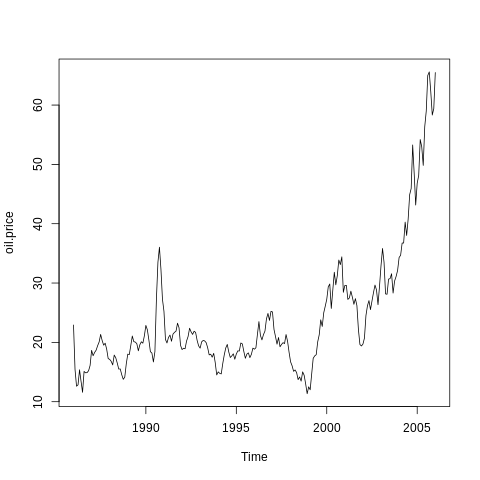

In [ ]:
%%R
data(oil.price)
plot(oil.price)

In [ ]:
from rpy2.robjects.packages import importr, data
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

In [ ]:
TSA=importr('TSA')
oil=data(TSA).fetch('oil.price')['oil.price']

In [ ]:
oil_df=pd.DataFrame(oil, columns=['minyak'])

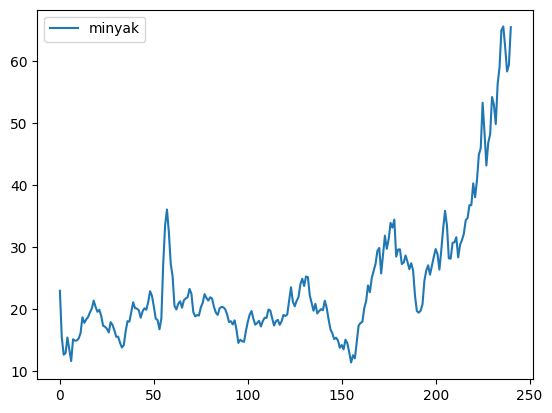

In [ ]:
oil_df.plot()
plt.show()

In [ ]:
adfuller(oil_df, autolag='AIC')[1]

np.float64(0.9974885123589682)

Berdasarkan plot deret tampak bahwa deret memiliki nilai tengah yang tidak konstan dan ragam yang tidak homogen. Hal ini mengindikasikan deret yang tidak stasioner. Hasil uji akar satuan Dickey-Fuller mendukung bahwa deret tidak stasioner, dimana $p-value>0.05$. Karena deret tidak stasioner dalam nilai tengah dan ragam, maka dilakukan transformasi logaritma dan pembedaan.

In [ ]:
oil_log=np.log(oil_df)

In [ ]:
adfuller(oil_log.diff().dropna(), autolag='AIC')[1]

np.float64(4.724887180156285e-13)

In [ ]:
!pip install PythonTsa

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 440.7/440.7 kB 5.8 MB/s eta 0:00:00


In [ ]:
from PythonTsa.plot_acf_pacf import acf_pacf_fig

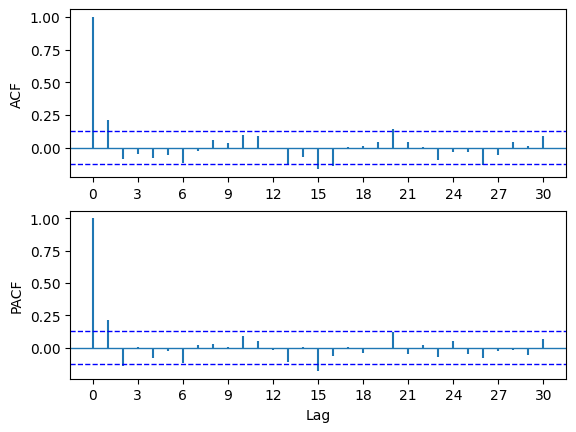

In [ ]:
acf_pacf_fig(oil_log.diff().dropna(), both=True, lag=30); plt.show()

Berdasarkan plot ACF dan PACF contoh di atas, model yang disarankan untuk deret adalah ARIMA (1,1,1). Model yang digunakan bersifat tentatif, bisa juga dicobakan model lain misalnya ARI (1,1), atau IMA (1,1). Pada ilustrasi ini dicobakan model IMA (1,1). Untuk model yang lain bisa anda coba.

In [ ]:
%%R
data(oil.price)
print(arima(log(oil.price),order=c(0,1,1),method='CSS'))
print(arima(log(oil.price),order=c(0,1,1),method='ML'))


Call:
arima(x = log(oil.price), order = c(0, 1, 1), method = "CSS")

Coefficients:
         ma1
      0.2731
s.e.  0.0681

sigma^2 estimated as 0.006731:  part log likelihood = 259.58

Call:
arima(x = log(oil.price), order = c(0, 1, 1), method = "ML")

Coefficients:
         ma1
      0.2956
s.e.  0.0693

sigma^2 estimated as 0.006689:  log likelihood = 260.29,  aic = -518.58


In [ ]:
print(ARIMA(oil_log,order=(0,1,1)).fit().summary())

                               SARIMAX Results                                
Dep. Variable:                 minyak   No. Observations:                  241
Model:                 ARIMA(0, 1, 1)   Log Likelihood                 260.291
Date:                Wed, 16 Apr 2025   AIC                           -516.583
Time:                        14:06:28   BIC                           -509.622
Sample:                             0   HQIC                          -513.778
                                - 241                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1          0.2956      0.054      5.445      0.000       0.189       0.402
sigma2         0.0067      0.000     16.403      0.000       0.006       0.007
Ljung-Box (L1) (Q):                   0.47   Jarque-

Penduga parameter model IMA(1,1) untuk deret harga bulanan satu barel minyak mentah menggunakan metode kuadrat terkecil adalah $\hat{\theta}=-0.2731$, sementara penduga parameter menggunakan metode kemungkinan maksimum adalah $\hat{\theta}=-0.2956$.

<h1> TUGAS KELOMPOK </h1>
1. Buatlah simulasi deret waktu (parameter yang digunakan bebas, tetapi berbeda dengan contoh yag sudah digunakan di atas) menggunakan seed 25xx, dimana xx adalah jumlah dua digit terakhir NIM anggota kelompok (misal NIM: 09 dan 28, maka seed yang digunakan 2537 . Lakukan pendugaan parameter menggunakan metode Kuadrat Terkecil dan Kemungkinan Maksimum:

Kelompok 1: ARIMA (0,0,1) dan ARIMA (2,2,2)

Kelompok 2: ARIMA (2,0,1) dan ARIMA (1,1,1)

Kelompok 3: ARIMA (1,0,1) dan ARIMA (1,1,2)

Kelompok 4: ARIMA (1,0,0) dan ARIMA (2,2,1)

Kelompok 5: ARIMA (2,0,0) dan ARIMA (2,1,1)

Kelompok 6: ARIMA (1,0,2) dan ARIMA (1,2,1)

Kelompok 7: ARIMA (0,0,2) dan ARIMA (1,2,2)

Kelompok 8: ARIMA (1,0,2) dan ARIMA (2,1,2)

Kelompok 9: ARIMA (2,0,2) dan ARIMA (1,2,1)

<rjust> 2. Ulangi langkah no.1 sebanyak 30 ulangan. Hitunglah bias dan ragam dari penduga parameter menggunakan metode Kuadrat Terkecil dan Kemungkinan Maksimum yang diperoleh dari 30 ulangan tersebut. Dan buatlah boxplot untuk memvisualisasikan bias dan ragam tersebut. Interpretasikan boxpot yang diperoleh </rjust>

<center><font size='4'> TERIMAKASIH </font></center><center>_LAY_ </center>